# Notebook 0 — Persiapan Data

Dataset: **Panoptic Indoor Segmentation v5** (Roboflow), diunduh dalam format **COCO Segmentation**.
Semua format lain diturunkan dari file COCO ini, jadi ketiga model memakai data yang persis sama.

Notebook ini dijalankan **sekali** (CPU saja, tidak memakai kuota GPU) dan menghasilkan satu file
`indoor_seg_data.zip` untuk Notebook 1–4. Isinya:

| Path di dalam zip | Isi | Dipakai oleh |
|---|---|---|
| `annotations/train_025.json`, `train_050.json`, `train_100.json` | COCO, subset data latih 25/50/100% (bertingkat: 25% ⊂ 50% ⊂ 100%) | Mask R-CNN, Mask2Former |
| `annotations/valid.json`, `annotations/test.json` | COCO, validasi & test asli (sama untuk semua run) | semua model + evaluasi pycocotools |
| `annotations/test_own.json` | COCO, test set buatan sendiri (kalau sudah diisi) | evaluasi domain shift |
| `images/<split>/` | gambar | semua model |
| `labels/<split>/` | label YOLO-seg hasil konversi dari COCO | YOLO |
| `data_025.yaml`, `data_050.yaml`, `data_100.yaml` | konfigurasi dataset YOLO | YOLO |
| `dataset_info.json`, `split_stats.csv` | daftar kelas, seed, statistik subset | laporan |

**Sebelum menjalankan:**
1. *Settings* → *Accelerator*: **None** (CPU cukup), *Internet*: **On**.
2. *Add-ons* → *Secrets* → tambahkan secret bernama `ROBOFLOW_API_KEY` berisi API key Roboflow kamu.
3. Sumber data sudah diisi: [panopticindoor/panoptic-indoor-segmentation](https://universe.roboflow.com/panopticindoor/panoptic-indoor-segmentation) versi 5.
4. Jalankan dengan **Save Version → Save & Run All** supaya hasilnya tersimpan sebagai output notebook.

In [1]:
!pip install -q roboflow pycocotools ultralytics

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


## 1. Konfigurasi

In [2]:
import contextlib
import io
import json
import random
import shutil
import time
import zipfile
from collections import Counter, defaultdict
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from PIL import Image
from pycocotools import mask as mask_utils
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from ultralytics.data.converter import merge_multi_segment

# ===== KONFIGURASI =====
ROBOFLOW_WORKSPACE = "panopticindoor"   # universe.roboflow.com/panopticindoor/panoptic-indoor-segmentation
ROBOFLOW_PROJECT   = "panoptic-indoor-segmentation"
ROBOFLOW_VERSION   = 5
ROBOFLOW_FORMAT    = "coco-segmentation"

# Test set buatan sendiri: isi setelah anotasinya selesai di Roboflow, lalu Save Version lagi.
# Semua split di project itu (train/valid/test) digabung menjadi satu split "test_own".
OWN_TEST_WORKSPACE = None
OWN_TEST_PROJECT   = None
OWN_TEST_VERSION   = None

SEED      = 42
FRACTIONS = [0.25, 0.50, 1.00]

RAW_DIR   = Path("/tmp/raw")          # hasil download mentah (tidak ikut disimpan)
DATA_ROOT = Path("/tmp/data")         # dataset olahan; notebook lain mengekstrak zip ke lokasi yang SAMA
OUT_DIR   = Path("/kaggle/working")   # hanya folder ini yang disimpan Kaggle
ZIP_NAME  = "indoor_seg_data.zip"

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## 2. Download dari Roboflow (format COCO Segmentation)

In [3]:
from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

assert "ISI_" not in ROBOFLOW_WORKSPACE + ROBOFLOW_PROJECT, "Isi ROBOFLOW_WORKSPACE dan ROBOFLOW_PROJECT dulu"
rf = Roboflow(api_key=UserSecretsClient().get_secret("ROBOFLOW_API_KEY"))


def download(workspace, project, version, dest):
    proj = rf.workspace(workspace).project(project)
    return proj.version(version).download(ROBOFLOW_FORMAT, location=str(dest), overwrite=True)


download(ROBOFLOW_WORKSPACE, ROBOFLOW_PROJECT, ROBOFLOW_VERSION, RAW_DIR / "main")
if OWN_TEST_PROJECT:
    download(OWN_TEST_WORKSPACE, OWN_TEST_PROJECT, OWN_TEST_VERSION, RAW_DIR / "own")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /tmp/raw/main in coco-segmentation:: 100%|██████████| 930/930 [00:00<00:00, 4894.64it/s]


In [4]:
SPLITS = ["train", "valid", "test"]


def load_split(root, split):
    p = Path(root) / split / "_annotations.coco.json"
    if not p.exists():
        return None
    with open(p, encoding="utf-8") as f:
        return json.load(f)


raw = {s: load_split(RAW_DIR / "main", s) for s in SPLITS}
missing = [s for s, d in raw.items() if d is None]
assert not missing, f"Split tidak ditemukan: {missing}. Cek isi folder {RAW_DIR / 'main'}"

for s, d in raw.items():
    print(f"{s:6s}: {len(d['images']):5d} gambar, {len(d['annotations']):6d} anotasi")

print("\nKategori di file COCO (train):")
for c in sorted(raw["train"]["categories"], key=lambda c: c["id"]):
    print(f"  id={c['id']:3d}  name={c['name']!r}  supercategory={c.get('supercategory')!r}")

train :   397 gambar,   4479 anotasi
valid :   166 gambar,   2022 anotasi
test  :   359 gambar,   5344 anotasi

Kategori di file COCO (train):
  id=  0  name='indoor-objects'  supercategory='none'
  id=  1  name='backpack'  supercategory='indoor-objects'
  id=  2  name='bed'  supercategory='indoor-objects'
  id=  3  name='blanket'  supercategory='indoor-objects'
  id=  4  name='book'  supercategory='indoor-objects'
  id=  5  name='bottle'  supercategory='indoor-objects'
  id=  6  name='bowl'  supercategory='indoor-objects'
  id=  7  name='box'  supercategory='indoor-objects'
  id=  8  name='cabinet-merged'  supercategory='indoor-objects'
  id=  9  name='cardboard'  supercategory='indoor-objects'
  id= 10  name='ceiling-merged'  supercategory='indoor-objects'
  id= 11  name='cell phone'  supercategory='indoor-objects'
  id= 12  name='chair'  supercategory='indoor-objects'
  id= 13  name='clock'  supercategory='indoor-objects'
  id= 14  name='couch'  supercategory='indoor-objects'
  id= 

## 3. Daftar kelas

Export COCO dari Roboflow biasanya punya kategori `id=0` berisi nama dataset (sebagai *supercategory*) yang
tidak punya anotasi. Kategori seperti itu dibuang. Kelas yang tersisa diberi id COCO baru **1..N**
(urutan sama dengan id asli) dan indeks YOLO **0..N-1**, sehingga `yolo_id = coco_id - 1` untuk semua notebook.

In [5]:
used_names = set()
for d in raw.values():
    id2name = {c["id"]: c["name"] for c in d["categories"]}
    used_names |= {id2name[a["category_id"]] for a in d["annotations"]}

ref_cats = sorted(raw["train"]["categories"], key=lambda c: c["id"])
CLASS_NAMES = [c["name"] for c in ref_cats if c["name"] in used_names]
extra = used_names - set(CLASS_NAMES)
assert not extra, f"Ada kelas di valid/test yang tidak ada di daftar kategori train: {extra}"

NAME2ID = {n: i + 1 for i, n in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)
CATEGORIES = [{"id": i, "name": n, "supercategory": "indoor"} for n, i in NAME2ID.items()]

dropped = [c["name"] for c in ref_cats if c["name"] not in used_names]
print(f"{NUM_CLASSES} kelas dipakai. Kategori dibuang (tanpa anotasi): {dropped}\n")
for n, i in NAME2ID.items():
    print(f"  COCO id {i:3d} | YOLO {i - 1:3d} | {n}")

74 kelas dipakai. Kategori dibuang (tanpa anotasi): ['indoor-objects']

  COCO id   1 | YOLO   0 | backpack
  COCO id   2 | YOLO   1 | bed
  COCO id   3 | YOLO   2 | blanket
  COCO id   4 | YOLO   3 | book
  COCO id   5 | YOLO   4 | bottle
  COCO id   6 | YOLO   5 | bowl
  COCO id   7 | YOLO   6 | box
  COCO id   8 | YOLO   7 | cabinet-merged
  COCO id   9 | YOLO   8 | cardboard
  COCO id  10 | YOLO   9 | ceiling-merged
  COCO id  11 | YOLO  10 | cell phone
  COCO id  12 | YOLO  11 | chair
  COCO id  13 | YOLO  12 | clock
  COCO id  14 | YOLO  13 | couch
  COCO id  15 | YOLO  14 | counter
  COCO id  16 | YOLO  15 | cup
  COCO id  17 | YOLO  16 | curtain
  COCO id  18 | YOLO  17 | dining table
  COCO id  19 | YOLO  18 | door-stuff
  COCO id  20 | YOLO  19 | fire-extinguisher
  COCO id  21 | YOLO  20 | floor-other-merged
  COCO id  22 | YOLO  21 | floor-wood
  COCO id  23 | YOLO  22 | flower
  COCO id  24 | YOLO  23 | food-other-merged
  COCO id  25 | YOLO  24 | fork
  COCO id  26 | YOLO

## 4. Bersihkan anotasi

Untuk setiap anotasi: poligon dengan kurang dari 3 titik atau luas 0 dibuang, koordinat di-*clip* ke dalam gambar,
`area` dihitung ulang dari mask (dipakai COCOeval untuk AP small/medium/large), dan `bbox` dihitung ulang dari poligon.
Id gambar dan anotasi dinomori ulang mulai dari 1, urut nama file, supaya hasilnya sama setiap kali dijalankan.

In [6]:
def polygons_from_rle(seg, h, w):
    rle = mask_utils.frPyObjects(seg, h, w) if isinstance(seg.get("counts"), list) else seg
    m = np.ascontiguousarray(mask_utils.decode(rle).astype(np.uint8))
    contours, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return [c.reshape(-1).astype(float).tolist() for c in contours]


def clean_polygons(seg, h, w):
    """List poligon valid (>= 3 titik, luas > 0), koordinat di-clip ke dalam gambar."""
    if isinstance(seg, dict):
        seg = polygons_from_rle(seg, h, w)
    out = []
    for poly in seg or []:
        pts = np.asarray(poly, dtype=float).reshape(-1, 2)
        pts[:, 0] = pts[:, 0].clip(0, w)
        pts[:, 1] = pts[:, 1].clip(0, h)
        if len(pts) >= 3 and cv2.contourArea(pts.astype(np.float32)) > 0:
            out.append(pts.reshape(-1).tolist())
    return out


def clean_split(d, label):
    id2name = {c["id"]: c["name"] for c in d["categories"]}
    anns_by_img = defaultdict(list)
    for a in d["annotations"]:
        anns_by_img[a["image_id"]].append(a)

    images, annotations, stats = [], [], Counter()
    for new_id, im in enumerate(sorted(d["images"], key=lambda x: x["file_name"]), start=1):
        h, w = int(im["height"]), int(im["width"])
        images.append({"id": new_id, "file_name": im["file_name"], "height": h, "width": w})
        for a in anns_by_img[im["id"]]:
            name = id2name[a["category_id"]]
            if name not in NAME2ID:
                raise ValueError(f"[{label}] kelas {name!r} tidak ada di daftar kelas dataset utama")
            polys = clean_polygons(a.get("segmentation"), h, w)
            if not polys:
                stats["dibuang: tanpa poligon valid"] += 1
                continue
            area = float(mask_utils.area(mask_utils.merge(mask_utils.frPyObjects(polys, h, w))))
            if area < 1:
                stats["dibuang: area 0"] += 1
                continue
            pts = np.concatenate([np.asarray(p).reshape(-1, 2) for p in polys])
            (x0, y0), (x1, y1) = pts.min(0), pts.max(0)
            if len(polys) > 1:
                stats["multi-poligon (objek terpotong)"] += 1
            annotations.append({
                "id": len(annotations) + 1, "image_id": new_id, "category_id": NAME2ID[name],
                "segmentation": polys, "area": area,
                "bbox": [float(x0), float(y0), float(x1 - x0), float(y1 - y0)], "iscrowd": 0,
            })
            stats["dipakai"] += 1
    coco = {"info": {"description": label}, "licenses": [],
            "images": images, "annotations": annotations, "categories": CATEGORIES}
    return coco, stats


clean = {}
for s in SPLITS:
    clean[s], st = clean_split(raw[s], f"main/{s}")
    print(f"{s:6s}: {dict(st)}")

train : {'dipakai': 4479}
valid : {'dipakai': 2022}
test  : {'dipakai': 5344}


## 5. Cek augmentasi dan kebocoran antar split

Roboflow menamai file `<nama-asli>_<ext>.rf.<hash>.<ext>`. Kalau versi dataset memakai augmentasi, satu foto asli
muncul beberapa kali di train dengan `<nama-asli>` sama tapi hash berbeda. Subset diambil **per foto asli**
supaya salinan augmentasi dari satu foto tidak terpecah ke subset yang berbeda.

In [7]:
def source_key(file_name):
    return file_name.split(".rf.")[0] if ".rf." in file_name else Path(file_name).stem


train_groups = defaultdict(list)
for im in clean["train"]["images"]:
    train_groups[source_key(im["file_name"])].append(im["id"])
group_sizes = Counter(len(v) for v in train_groups.values())
AUGMENTED = max(group_sizes) > 1

print(f"train: {len(clean['train']['images'])} gambar dari {len(train_groups)} foto asli")
print("jumlah gambar per foto asli -> banyaknya foto:", dict(sorted(group_sizes.items())))
if AUGMENTED:
    n_multi = sum(1 for v in train_groups.values() if len(v) > 1)
    print(f"-> {n_multi} foto asli muncul lebih dari sekali. "
          + ("Kemungkinan augmentasi Roboflow." if n_multi > 0.2 * len(train_groups)
             else "Jumlahnya sedikit, jadi kemungkinan foto duplikat, bukan augmentasi."))

keys = {s: {source_key(im["file_name"]) for im in clean[s]["images"]} for s in SPLITS}
for a, b in [("train", "valid"), ("train", "test"), ("valid", "test")]:
    n = len(keys[a] & keys[b])
    print(f"foto asli yang sama di {a} & {b}: {n}" + ("   <-- catat di laporan" if n else ""))

train: 397 gambar dari 396 foto asli
jumlah gambar per foto asli -> banyaknya foto: {1: 395, 2: 1}
-> 1 foto asli muncul lebih dari sekali. Jumlahnya sedikit, jadi kemungkinan foto duplikat, bukan augmentasi.
foto asli yang sama di train & valid: 0
foto asli yang sama di train & test: 0
foto asli yang sama di valid & test: 0


## 6. Subset bertingkat 25% / 50% / 100%

Foto asli diurutkan secara acak (seed tetap), lalu dipilih satu per satu secara *greedy*: setiap langkah mengambil
foto yang berisi kelas dengan kekurangan relatif terbesar terhadap proporsi data penuh (kalau seri, kelas yang lebih langka
didahulukan). Subset fraksi *f* adalah awalan urutan ini sampai jumlah gambarnya mencapai *f* × total, sehingga
25% ⊂ 50% ⊂ 100% dan proporsi kelas tiap subset mendekati data penuh. Validasi dan test **tidak** diubah.

In [8]:
assert 1.0 in FRACTIONS, "FRACTIONS harus berisi 1.0"
FS = sorted(FRACTIONS)
TAGS = {f: f"{round(f * 100):03d}" for f in FS}   # 0.25 -> "025"


def class_counts(img_ids, coco):
    ids, cnt = set(img_ids), np.zeros(NUM_CLASSES, dtype=int)
    for a in coco["annotations"]:
        if a["image_id"] in ids:
            cnt[a["category_id"] - 1] += 1
    return cnt


def build_nested_subsets(groups, coco, fractions, seed):
    per_img = defaultdict(lambda: np.zeros(NUM_CLASSES, dtype=int))
    for a in coco["annotations"]:
        per_img[a["image_id"]][a["category_id"] - 1] += 1
    g_cnt = {k: sum((per_img[i] for i in ids), np.zeros(NUM_CLASSES, dtype=int)) for k, ids in groups.items()}
    g_size = {k: len(ids) for k, ids in groups.items()}

    rng = random.Random(seed)
    remaining = sorted(groups)
    rng.shuffle(remaining)
    total = sum(g_cnt.values())
    total_imgs = sum(g_size.values())

    order, cur, cur_imgs, subsets = [], np.zeros(NUM_CLASSES), 0, {}
    for f in sorted(fractions):
        target_imgs = round(f * total_imgs)
        while cur_imgs < target_imgs and remaining:
            deficit = np.where(total > 0, np.round((f * total - cur) / np.maximum(total, 1), 9), -np.inf)
            pick = None
            for c in sorted(range(NUM_CLASSES), key=lambda c: (-deficit[c], total[c])):
                if deficit[c] <= 0:
                    break
                pick = next((k for k in remaining if g_cnt[k][c] > 0), None)
                if pick is not None:
                    break
            if pick is None:
                pick = remaining[0]
            remaining.remove(pick)
            order.append(pick)
            cur += g_cnt[pick]
            cur_imgs += g_size[pick]
        subsets[f] = sorted(i for k in order for i in groups[k])
    return subsets


subsets = build_nested_subsets(train_groups, clean["train"], FS, SEED)

for a, b in zip(FS, FS[1:]):
    assert set(subsets[a]) <= set(subsets[b]), "subset tidak bertingkat!"
assert len(subsets[1.0]) == len(clean["train"]["images"])

counts = {f: class_counts(subsets[f], clean["train"]) for f in FS}
stats_df = pd.DataFrame({"kelas": CLASS_NAMES})
for f in FS:
    stats_df[f"inst_{TAGS[f]}"] = counts[f]
    if f < 1.0:
        stats_df[f"%_{TAGS[f]}"] = (100 * counts[f] / np.maximum(counts[1.0], 1)).round(1)
stats_df["inst_valid"] = class_counts([im["id"] for im in clean["valid"]["images"]], clean["valid"])
stats_df["inst_test"] = class_counts([im["id"] for im in clean["test"]["images"]], clean["test"])
print(stats_df.to_string(index=False), "\n")

n_train = len(clean["train"]["images"])
for f in FS:
    print(f"subset {TAGS[f]}: {len(subsets[f]):5d} gambar ({100 * len(subsets[f]) / n_train:5.1f}%), "
          f"{counts[f].sum():6d} instance")
absent = [CLASS_NAMES[i] for i in np.where((counts[FS[0]] == 0) & (counts[1.0] > 0))[0]]
print("\nPERINGATAN: kelas yang ada di train tapi tidak muncul di subset terkecil: " + str(absent) if absent
      else "\nSemua kelas yang ada di train juga muncul di subset terkecil.")
UNSEEN = [n for n, c in zip(CLASS_NAMES, counts[1.0]) if c == 0]
if UNSEEN:
    print(f"PERINGATAN: {len(UNSEEN)} kelas tidak punya satu pun instance di train (model tidak bisa mempelajarinya, "
          f"AP-nya akan 0 untuk semua model):\n  {UNSEEN}")

             kelas  inst_025  %_025  inst_050  %_050  inst_100  inst_valid  inst_test
          backpack         2   66.7         2   66.7         3           2         31
               bed        14   53.8        19   73.1        26           6         71
           blanket         7   36.8        10   52.6        19           6         13
              book        28   26.7        54   51.4       105          15        349
            bottle        44   71.0        47   75.8        62          10         58
              bowl        16   24.6        37   56.9        65          40         76
               box        25   26.3        45   47.4        95          85          1
    cabinet-merged        16   34.0        32   68.1        47          19        110
         cardboard         1   50.0         1   50.0         2           0         14
    ceiling-merged        32   41.6        49   63.6        77          28        149
        cell phone         2   25.0         4   50.0  

## 7. Test set buatan sendiri (opsional, diisi nanti)

Dijalankan hanya kalau `OWN_TEST_PROJECT` sudah diisi. Nama kelas harus **sama persis** dengan dataset utama.
Ukuran gambar dibandingkan dengan test asli: kalau berbeda jauh, samakan *preprocessing* versi Roboflow-nya
(auto-orient dan resize) dengan versi 5 dataset utama, supaya selisih performa memang karena *domain shift*.

In [9]:
own_clean, own_src = None, {}
if OWN_TEST_PROJECT:
    merged = {"images": [], "annotations": [], "categories": None}
    for s in SPLITS:
        d = load_split(RAW_DIR / "own", s)
        if d is None:
            continue
        merged["categories"] = merged["categories"] or d["categories"]
        remap = {}
        for im in d["images"]:
            remap[im["id"]] = len(merged["images"])
            own_src[im["file_name"]] = RAW_DIR / "own" / s
            merged["images"].append({**im, "id": remap[im["id"]]})
        for a in d["annotations"]:
            merged["annotations"].append({**a, "id": len(merged["annotations"]), "image_id": remap[a["image_id"]]})
    assert merged["images"], f"Tidak ada gambar di {RAW_DIR / 'own'}"
    own_clean, st = clean_split(merged, "own/test_own")
    print(f"test_own: {len(own_clean['images'])} gambar, {dict(st)}")
    own_counts = class_counts([im["id"] for im in own_clean["images"]], own_clean)
    stats_df["inst_test_own"] = own_counts
    print("kelas tanpa instance di test_own:", [n for n, c in zip(CLASS_NAMES, own_counts) if c == 0])
    for name, c in [("test asli", clean["test"]), ("test_own", own_clean)]:
        sizes = Counter((im["width"], im["height"]) for im in c["images"]).most_common(3)
        print(f"ukuran gambar terbanyak di {name}: {sizes}")
else:
    print("OWN_TEST_PROJECT belum diisi, bagian ini dilewati.")

OWN_TEST_PROJECT belum diisi, bagian ini dilewati.


## 8. Tulis dataset: COCO + label YOLO-seg + YAML

Anotasi yang terdiri dari beberapa poligon (objek terpotong karena tertutup objek lain) digabung menjadi satu poligon
untuk YOLO memakai `merge_multi_segment` dari Ultralytics, cara yang sama dengan konverter COCO resmi Ultralytics.
File COCO tetap menyimpan poligon aslinya.

In [10]:
if DATA_ROOT.exists():
    shutil.rmtree(DATA_ROOT)
(DATA_ROOT / "annotations").mkdir(parents=True)


def write_json(obj, path, indent=None):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=indent)


def subset_coco(coco, img_ids):
    ids = set(img_ids)
    return {**coco,
            "images": [im for im in coco["images"] if im["id"] in ids],
            "annotations": [a for a in coco["annotations"] if a["image_id"] in ids]}


def yolo_lines(coco):
    anns = defaultdict(list)
    for a in coco["annotations"]:
        anns[a["image_id"]].append(a)
    out = {}
    for im in coco["images"]:
        wh = np.array([im["width"], im["height"]], dtype=float)
        lines = []
        for a in anns[im["id"]]:
            segs = a["segmentation"]
            if len(segs) > 1:
                pts = np.concatenate(merge_multi_segment(segs), axis=0)
            else:
                pts = np.asarray(segs[0], dtype=float).reshape(-1, 2)
            pts = (pts / wh).clip(0, 1).reshape(-1)
            lines.append(" ".join([str(a["category_id"] - 1)] + [f"{v:.6f}" for v in pts]))
        out[im["file_name"]] = lines
    return out


def export_split(coco, src_dirs, split):
    img_dir, lbl_dir = DATA_ROOT / "images" / split, DATA_ROOT / "labels" / split
    img_dir.mkdir(parents=True)
    lbl_dir.mkdir(parents=True)
    for fn, lines in yolo_lines(coco).items():
        shutil.copy2(Path(src_dirs[fn]) / fn, img_dir / fn)
        (lbl_dir / (Path(fn).stem + ".txt")).write_text("\n".join(lines), encoding="utf-8")


exported = {}
for s in SPLITS:
    export_split(clean[s], {im["file_name"]: RAW_DIR / "main" / s for im in clean[s]["images"]}, s)
    exported[s] = clean[s]
write_json(clean["valid"], DATA_ROOT / "annotations" / "valid.json")
write_json(clean["test"], DATA_ROOT / "annotations" / "test.json")

if own_clean:
    export_split(own_clean, own_src, "test_own")
    exported["test_own"] = own_clean
    write_json(own_clean, DATA_ROOT / "annotations" / "test_own.json")

id2fn = {im["id"]: im["file_name"] for im in clean["train"]["images"]}
for f in FS:
    tag = TAGS[f]
    write_json(subset_coco(clean["train"], subsets[f]), DATA_ROOT / "annotations" / f"train_{tag}.json")
    (DATA_ROOT / f"train_{tag}.txt").write_text(
        "\n".join(f"./images/train/{id2fn[i]}" for i in subsets[f]), encoding="utf-8")
    cfg = {"path": DATA_ROOT.as_posix(), "train": f"train_{tag}.txt", "val": "images/valid", "test": "images/test",
           "names": {i: n for i, n in enumerate(CLASS_NAMES)}}
    with open(DATA_ROOT / f"data_{tag}.yaml", "w", encoding="utf-8") as fh:
        yaml.safe_dump(cfg, fh, sort_keys=False, allow_unicode=True)

print("Dataset ditulis ke", DATA_ROOT)
for p in sorted(DATA_ROOT.iterdir()):
    print("  ", p.name)

Dataset ditulis ke /tmp/data
   annotations
   data_025.yaml
   data_050.yaml
   data_100.yaml
   images
   labels
   train_025.txt
   train_050.txt
   train_100.txt


## 9. Verifikasi

In [11]:
# (a) Semua file COCO terbaca pycocotools
for p in sorted((DATA_ROOT / "annotations").glob("*.json")):
    with contextlib.redirect_stdout(io.StringIO()):
        c = COCO(str(p))
    print(f"{p.name:16s} {len(c.imgs):5d} gambar  {len(c.anns):6d} anotasi")

# (b) Evaluasi GT terhadap dirinya sendiri (cek format COCOeval).
#     COCOeval standar hanya menghitung 100 deteksi per gambar per kelas. Gambar yang punya > 100 instance
#     satu kelas membuat AP maksimum < 1, jadi cek format memakai batas 10000, dan batas standar 100
#     dilaporkan sebagai AP maksimum yang mungkin dicapai model.
def gt_vs_gt_ap(json_path):
    """Mask AP (area=all) untuk batas 10000 dan 100 deteksi, dihitung dari tabel presisi COCOeval.
    (ev.stats[0] tidak dipakai karena pycocotools selalu menghitungnya pada batas 100.)"""
    with contextlib.redirect_stdout(io.StringIO()):
        gt = COCO(str(json_path))
        dets = [{"image_id": a["image_id"], "category_id": a["category_id"],
                 "segmentation": gt.annToRLE(a), "score": 1.0} for a in gt.dataset["annotations"]]
        ev = COCOeval(gt, gt.loadRes(dets), "segm")
        ev.params.maxDets = [1, 100, 10_000]
        ev.evaluate(); ev.accumulate()
    prec = ev.eval["precision"][:, :, :, 0, :]          # IoU x recall x kelas x maxDets
    ap = [float(prec[..., m][prec[..., m] > -1].mean()) for m in range(3)]
    return ap[2], ap[1]


print()
for s in exported:
    p = DATA_ROOT / "annotations" / f"{s}.json"
    if not p.exists():
        continue
    full, std = gt_vs_gt_ap(p)
    print(f"{s:9s} GT vs GT mask AP: batas 10000 = {full:.4f} (harus 1.0000) | "
          f"batas standar 100 = {std:.4f} (AP maksimum yang mungkin)")
    assert abs(full - 1.0) < 1e-6, f"format COCO {s} bermasalah"

# Gambar padat: instance satu kelas > 100 dalam satu gambar
print()
id2name = {i: n for n, i in NAME2ID.items()}
for s, c in exported.items():
    fn = {im["id"]: im["file_name"] for im in c["images"]}
    per_img = Counter(a["image_id"] for a in c["annotations"])
    per_img_cls = Counter((a["image_id"], a["category_id"]) for a in c["annotations"])
    crowded = [(fn[i], id2name[k], n) for (i, k), n in per_img_cls.items() if n > 100]
    print(f"{s:9s} maks {max(per_img.values(), default=0):4d} instance/gambar, "
          f"maks {max(per_img_cls.values(), default=0):4d} instance satu kelas/gambar"
          + (f"  -> gambar padat (>100 satu kelas): {crowded}" if crowded else ""))

# (c) Jumlah baris label YOLO = jumlah anotasi COCO, dan ukuran file gambar = ukuran di JSON


def effective_size(path):
    with Image.open(path) as im:
        w, h = im.size
        if im.getexif().get(0x0112, 1) in (5, 6, 7, 8):   # EXIF rotasi 90 derajat
            w, h = h, w
    return w, h


for s, c in exported.items():
    n_ann = Counter(a["image_id"] for a in c["annotations"])
    bad_lbl = bad_size = 0
    for im in c["images"]:
        txt = (DATA_ROOT / "labels" / s / (Path(im["file_name"]).stem + ".txt")).read_text(encoding="utf-8").strip()
        bad_lbl += (len(txt.splitlines()) if txt else 0) != n_ann[im["id"]]
        bad_size += effective_size(DATA_ROOT / "images" / s / im["file_name"]) != (im["width"], im["height"])
    print(f"{s:9s} label tidak cocok: {bad_lbl}   ukuran gambar tidak cocok: {bad_size}")

test.json          359 gambar    5344 anotasi
train_025.json      99 gambar    1339 anotasi
train_050.json     198 gambar    2510 anotasi
train_100.json     397 gambar    4479 anotasi
valid.json         166 gambar    2022 anotasi

valid     GT vs GT mask AP: batas 10000 = 1.0000 (harus 1.0000) | batas standar 100 = 1.0000 (AP maksimum yang mungkin)
test      GT vs GT mask AP: batas 10000 = 1.0000 (harus 1.0000) | batas standar 100 = 0.9994 (AP maksimum yang mungkin)

train     maks   61 instance/gambar, maks   36 instance satu kelas/gambar
valid     maks   79 instance/gambar, maks   46 instance satu kelas/gambar
test      maks  129 instance/gambar, maks  111 instance satu kelas/gambar  -> gambar padat (>100 satu kelas): [('173_jpg.rf.8e2e8a811bd4a9b2ac10a2f2f4ca9d54.jpg', 'book', 111)]
train     label tidak cocok: 0   ukuran gambar tidak cocok: 2
valid     label tidak cocok: 0   ukuran gambar tidak cocok: 2
test      label tidak cocok: 0   ukuran gambar tidak cocok: 0


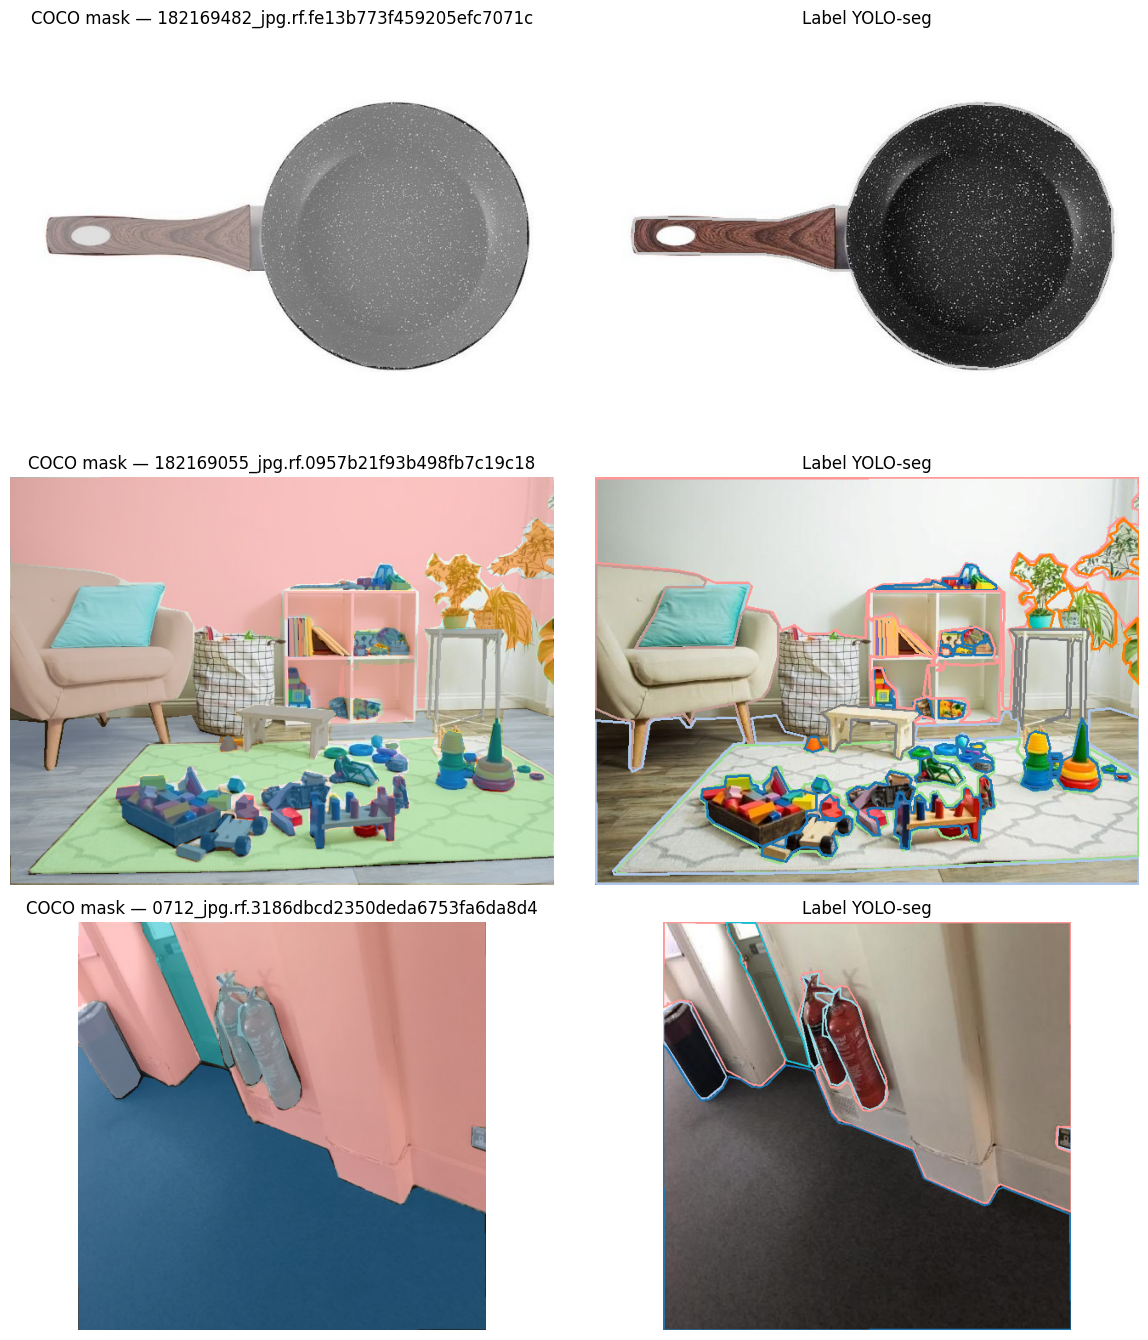

In [12]:
# (d) Visual: mask dari COCO (kiri) vs poligon YOLO (kanan) untuk beberapa gambar train
palette = (plt.cm.tab20(np.arange(20))[:, :3] * 255).astype(int)
anns_by_img = defaultdict(list)
for a in clean["train"]["annotations"]:
    anns_by_img[a["image_id"]].append(a)
with_anns = [im for im in clean["train"]["images"] if anns_by_img[im["id"]]]
samples = random.Random(SEED).sample(with_anns, k=min(3, len(with_anns)))

fig, axes = plt.subplots(len(samples), 2, figsize=(12, 4.5 * len(samples)), squeeze=False)
for row, im in zip(axes, samples):
    img = cv2.cvtColor(cv2.imread(str(DATA_ROOT / "images" / "train" / im["file_name"])), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    left, right = img.copy(), img.copy()
    for a in anns_by_img[im["id"]]:
        m = mask_utils.decode(mask_utils.merge(mask_utils.frPyObjects(a["segmentation"], h, w))).astype(bool)
        left[m] = (0.45 * left[m] + 0.55 * palette[(a["category_id"] - 1) % 20]).astype(np.uint8)
    for line in (DATA_ROOT / "labels" / "train" / (Path(im["file_name"]).stem + ".txt")).read_text().splitlines():
        v = line.split()
        pts = (np.array(v[1:], dtype=float).reshape(-1, 2) * [w, h]).round().astype(np.int32)
        cv2.polylines(right, [pts], True, tuple(int(x) for x in palette[int(v[0]) % 20]), 2)
    row[0].imshow(left); row[0].set_title(f"COCO mask — {im['file_name'][:40]}")
    row[1].imshow(right); row[1].set_title("Label YOLO-seg")
    for ax in row:
        ax.axis("off")
plt.tight_layout()
OUT_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(OUT_DIR / "cek_konversi.png", dpi=80)
plt.show()

## 10. Simpan sebagai zip

In [13]:
info = {
    "source": {"workspace": ROBOFLOW_WORKSPACE, "project": ROBOFLOW_PROJECT,
               "version": ROBOFLOW_VERSION, "format": ROBOFLOW_FORMAT},
    "own_test": ({"workspace": OWN_TEST_WORKSPACE, "project": OWN_TEST_PROJECT, "version": OWN_TEST_VERSION}
                 if OWN_TEST_PROJECT else None),
    "seed": SEED,
    "fractions": FS,
    "classes": [{"coco_id": i, "yolo_id": i - 1, "name": n} for n, i in NAME2ID.items()],
    "classes_unseen_in_train": UNSEEN,
    "train_source_photos": len(train_groups),
    "train_augmented_copies_detected": bool(AUGMENTED),
    "subsets": {TAGS[f]: {"images": len(subsets[f]), "instances": int(counts[f].sum())} for f in FS},
    "splits": {s: {"images": len(c["images"]), "instances": len(c["annotations"])} for s, c in exported.items()},
    "data_root": DATA_ROOT.as_posix(),
    "created": time.strftime("%Y-%m-%d %H:%M:%S"),
}
write_json(info, DATA_ROOT / "dataset_info.json", indent=2)
stats_df.to_csv(DATA_ROOT / "split_stats.csv", index=False)

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
zip_path = OUT_DIR / ZIP_NAME
with zipfile.ZipFile(zip_path, "w") as z:
    for p in sorted(DATA_ROOT.rglob("*")):
        if p.is_file() and p.suffix != ".cache":
            z.write(p, p.relative_to(DATA_ROOT).as_posix(),
                    compress_type=zipfile.ZIP_STORED if p.suffix.lower() in IMG_EXT else zipfile.ZIP_DEFLATED)
for name in ["dataset_info.json", "split_stats.csv"]:
    shutil.copy2(DATA_ROOT / name, OUT_DIR / name)

print(f"{zip_path}  ({zip_path.stat().st_size / 1e6:.1f} MB)")
print(json.dumps(info["subsets"], indent=2))

/kaggle/working/indoor_seg_data.zip  (58.7 MB)
{
  "025": {
    "images": 99,
    "instances": 1339
  },
  "050": {
    "images": 198,
    "instances": 2510
  },
  "100": {
    "images": 397,
    "instances": 4479
  }
}


## Cara memakai di Notebook 1–4

Di Notebook 1–4: *Add Input* → *Notebooks* → pilih notebook ini. Notebook-notebook itu sudah mengekstrak
`indoor_seg_data.zip` ke `/tmp/data` dan menyesuaikan path di file YAML YOLO secara otomatis.

- **YOLO** memakai `data_025.yaml` / `data_050.yaml` / `data_100.yaml`.
- **Mask R-CNN** dan **Mask2Former** memakai `annotations/train_<fraksi>.json` + `images/train/`, dan
  `annotations/valid.json` untuk memilih bobot terbaik.
- **Semua model** dievaluasi pada `annotations/test.json` (dan `test_own.json` kalau ada).

Kalau test set buatan sendiri sudah siap, isi `OWN_TEST_*` di sel konfigurasi lalu **Save Version** lagi.
Subset 25/50/100% tidak berubah karena seed dan urutan file sama; bandingkan `dataset_info.json` versi lama dan baru
untuk memastikannya.